In [1]:
%pip install statsmodels

  Obtaining dependency information for statsmodels from https://files.pythonhosted.org/packages/b8/be/77c4b5d3f61eab5676981d20f705acee8222ad31de8aca42a331dcd4cfdb/statsmodels-0.15.0-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for patsy>=0.5.6 from https://files.pythonhosted.org/packages/20/70/cd3cf5cff538323076a879edef02cce6f13f7d75e03d12f211b0a0dbd178/patsy-1.0.3-py2.py3-none-any.whl.metadata
  Obtaining dependency information for formulaic>=1.1.0 from https://files.pythonhosted.org/packages/fc/75/0576b03f7889ad25b5385b4f6c69e0543713425a6f193b056c9b0a2e65ce/formulaic-1.2.2-py3-none-any.whl.metadata
  Obtaining dependency information for interface-meta>=1.2.0 from https://files.pythonhosted.org/packages/a1/d3/20a61a248feb1249cd81f83ce731f0bdf5170ed96a08a298f7081cda9e90/interface_meta-2.0.1-py3-none-any.whl.metadata
  Obtaining dependency information for wrapt>=1.0 from https://files.pythonhosted.org/packages/e6/d4/ae9ca837038a7a9aadb906eeca76b42df54e299edb29f8


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [4]:
df=pd.read_csv(r"wine_quality_cleaned.csv")
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7


In [5]:
X=df[["alcohol","volatile acidity","density","pH","sulphates"]]
y=df["quality"]

In [6]:
X=sm.add_constant(X)

In [8]:
model=sm.OLS(y,X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                quality   R-squared:                       0.250
Model:                            OLS   Adj. R-squared:                  0.249
Method:                 Least Squares   F-statistic:                     325.9
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          4.08e-302
Time:                        14:54:01   Log-Likelihood:                -5650.4
No. Observations:                4898   AIC:                         1.131e+04
Df Residuals:                    4892   BIC:                         1.135e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              -35.0884      6.023  

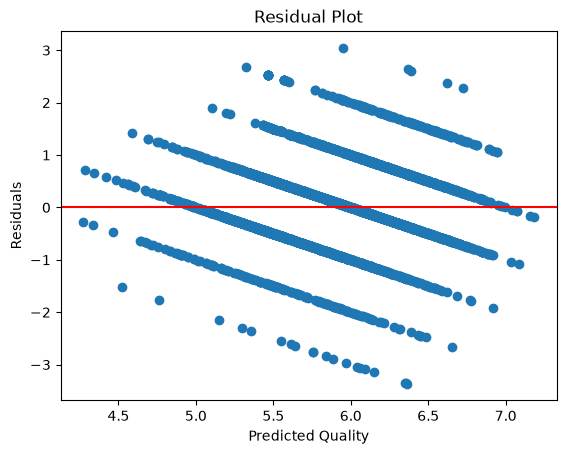

In [9]:
residuals=model.resid
plt.scatter(model.fittedvalues, residuals)
plt.axhline(y=0, color="red")
plt.title("Residual Plot")
plt.xlabel("Predicted Quality")
plt.ylabel("Residuals")
plt.show()

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])]
print(vif)

           Variable       VIF
0             const  1.000000
1           alcohol  2.634814
2  volatile acidity  1.024874
3           density  2.625552
4                pH  1.042787
5         sulphates  1.038163
